## Grafo autore-autore

In [1]:
import networkx as nx
import pandas as pd
import json
import matplotlib.pyplot as plt
import scipy
import numpy as np
import powerlaw
from networkx.algorithms import bipartite

In [2]:
filename = 'Data/grafo.csv'
g = nx.read_edgelist(filename, delimiter=",")

In [3]:
print(f'Il grafo ha i seguenti nodi: {g.nodes}')
print(f'Il grafo ha {g.number_of_nodes()} nodi e {g.number_of_edges()} links')

Il grafo ha i seguenti nodi: ['Alessandro Liberati', 'Silvia Pregno', 'Massimo Brunetti', 'Holger J. Schünemann', 'Valter Torri', 'Ivan Moschetti', 'V.L. Pecoraro', 'Francesca Fulceri', 'Daniele Piovani', 'Stefanos Bonovas', 'Marco Vinceti', 'Tommaso Filippini', 'Laura Maria Fatta', 'Angela Caruso', 'Antonio Ciaramella', 'Nicola De Stefano', 'Marco Battaglini', 'Maria De Luca', 'Mark W. Woolrich', 'Antonio Federico', 'Marilena De Luca', 'Maria Pia Amato', 'Valentina Zipoli', 'Antonio Giorgio', 'Ralph H. B. Benedict', 'Christian Enzinger', 'Jeroen J.G. Geurts', 'Matilde Inglese', 'Marcello Moccia', 'Massimiliano Calabrese', 'Benedetta Goretti', 'Maria Laura Stromillo', 'Claudia A. M. Gandini Wheeler‐Kingshott', 'Maria Pia Sormani', 'Anna Maria Repice', 'Cristiano Scandurra', 'Giovanna Borriello', 'Francesca Trojsi', 'Alvino Bisecco', 'Simona Bonavita', 'Luigi Lavorgna', 'M. Bartolozzi', 'M. Mortilla', 'Leonello Guidi', 'Gianfranco Siracusa', 'Angelo Ghezzi', 'Marco Roscio', 'Alfonso Iud

In [4]:
print(f'L\'average degree è di: {sum(dict(g.degree()).values())/float(len(g)):.2f}')
print(f'La densità del grafo è {nx.density(g)}.')

L'average degree è di: 12.35
La densità del grafo è 0.00011990788342610632.


 La densità di un grafo rappresenta il rapporto tra il numero di link presenti ed il numero di link che potrebbero potenzialmente esistere in un grafo. Nel caso di questo particolare grafo, la densità è dello 0.01%, molto bassa, il che implica che i nodi presenti all'interno del grafo sono scarsamente connessi o esistono cluster di essi che non comunicano tra loro. La maggior parte dei network complessi hanno una densità molto bassa.

Calculating best minimal value for power law fit


/var/folders/32/wr6jfczj32q0c3fcn7fkrtvr0000gn/T/ipykernel_1683/2493451360.py:14: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  plt.xlim((min(degree), max(degree)))


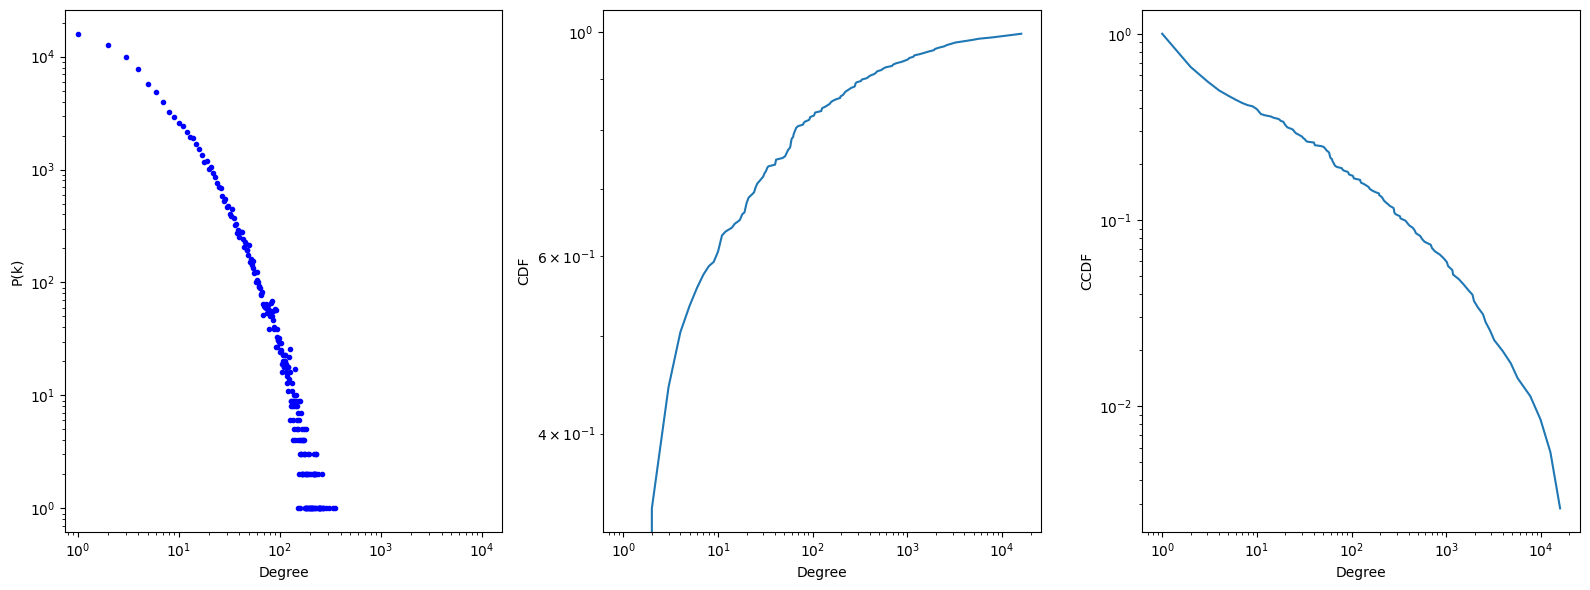

In [5]:
def plot_dist(G):
    M = nx.to_scipy_sparse_array(G)
    xmin = min([d[1] for d in G.degree()])
    indegrees = M.sum(0).ravel()
    degree = np.bincount(indegrees)
    fit = powerlaw.Fit(np.array(degree)+1, fit_method='KS')#, xmin=xmin, xmax=max(degree)-xmin,discrete=True)
    
    
    fig = plt.figure(figsize=(16, 6)) 
    """ Plot Distribution """
    plt.subplot(1, 3, 1)
    plt.plot(range(len(degree)),degree,'b.')   
    plt.loglog()
    plt.xlim((min(degree), max(degree)))
    plt.xlabel('Degree')
    plt.ylabel('P(k)')


    """ Plot CDF """
    plt.subplot(1, 3, 2)
    fit.plot_cdf()
    plt.xlabel("Degree")
    plt.ylabel('CDF')

    """ Plot CCDF """
    plt.subplot(1, 3, 3)
    fit.plot_ccdf()
    plt.ylabel('CCDF')
    plt.xlabel('Degree')
    plt.tight_layout()
    plt.show()

plot_dist(g)

- Grafo 1: distribuzione del grado all'interno della rete. Segue una chiara legge di potenza/zipfiana, con pochissimi nodi che hanno una grado molto alto e la maggior parte degli altri che si attesta attorno ad 1 e gradi appena superiori.
- Grafo 2: comulative distribution function. Notiamo come il numero maggiore di nodi abbia un grado piuttosto basso, anche se la curva cresce esponenzialmente fino a che non si stabilizza attorno alle poche decine e poi ad 1 per il grado maggiore.
- Grafo 3: complementary comulative distribution function. Mostra il complemento del calcolo precedente.

#### Ego network del nodo maggiormente connesso

In [6]:
node, degree = max(g.degree(), key=lambda x: x[1])
print(f'Il nodo maggiormente connesso all\'interno del grafo è {node} con degree {degree}')

Il nodo maggiormente connesso all'interno del grafo è Guido Barbiellini con degree 352


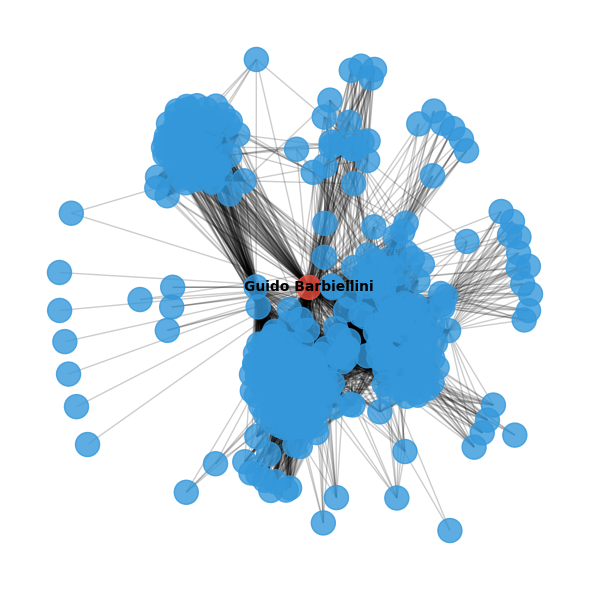

In [8]:
ego = nx.ego_graph(g, node) 
layout = nx.fruchterman_reingold_layout(ego)

plt.figure(figsize=(6, 6))
degrees = dict(ego.degree())

node_colors = ['#e74c3c' if n == node else '#3498db' for n in ego.nodes()] # colore diverso per il nodo centrale
nx.draw_networkx_nodes(ego, layout,
                       node_color=node_colors,
                       alpha=0.8)

nx.draw_networkx_edges(ego, layout, 
                       alpha=0.2,
                       width=1,
                       edge_color='black')

# per visualizzare il nome dell'ego
nx.draw_networkx_labels(ego, layout, 
                        labels={node: node},
                        font_size=10,
                        font_weight='bold')

plt.axis('off')
plt.tight_layout()
plt.show()

#### Connected Components

In [8]:
num_connected_components = nx.number_connected_components(g)
connected_components = sorted(nx.connected_components(g), key=len, reverse=True)

print(f'All\'interno del grafo ci sono {num_connected_components} connected components')
# calcolo del giant connected component-> in genere contiene tra l'80 ed il 100% dei nodi
gcc = connected_components[0]
second_cc = connected_components[1]
print(f'Il giant connected component contiene {len(gcc)} nodi, ovvero il {(len(gcc)/102965)*100:.2f}% del totale.')
print(f'Il secondo connected component per larghezza contiene {len(second_cc)} nodi, lo {(len(second_cc)/102965)*100:.2f}% del totale.')

All'interno del grafo ci sono 910 connected components
Il giant connected component contiene 99409 nodi, ovvero il 96.55% del totale.
Il secondo connected component per larghezza contiene 21 nodi, lo 0.02% del totale.


provare a pesare il numero di collaborazioni tra autori e vedere quanto velocemente collassa la rete rimuovendo gli archi in base al peso-> levando gli archi potrebbero apparire componenti di dimensioni minore. 

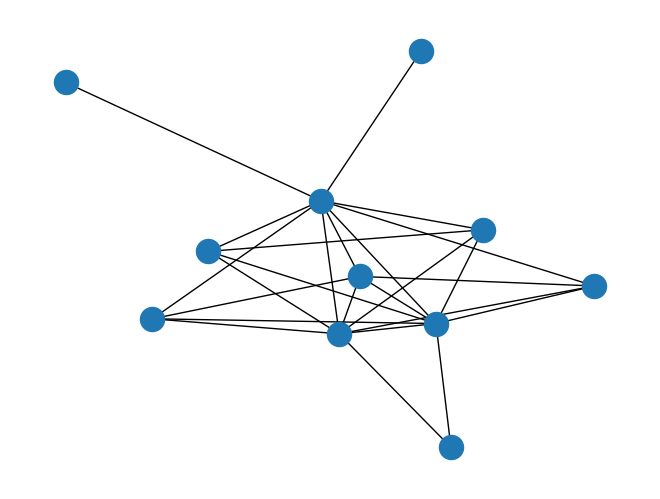

In [9]:
comps = list(nx.connected_components(g))
comp_1 = nx.subgraph(g, comps[1])
nx.draw(comp_1)

In [10]:
# plt.figure(figsize=(10, 6))
# pos = nx.spring_layout(g, k=3, iterations=50, seed=42)

# # Assegna un colore diverso a ogni componente
# colors = plt.cm.Set3(range(len(comps)))
# node_colors = []
# for node in g.nodes():
#     for i, comp in enumerate(comps):
#         if node in comp:
#             node_colors.append(colors[i])
#             break

# degrees = dict(g.degree())
# node_sizes = [300 + degrees[n] * 100 for n in g.nodes()]

# nx.draw_networkx_nodes(g, pos,
#                        node_size=node_sizes,
#                        node_color=node_colors,
#                        alpha=0.8,
#                        edgecolors='black',
#                        linewidths=1.5)

# nx.draw_networkx_edges(g, pos,
#                        alpha=0.3,
#                        width=1.5)

# plt.title(f'{len(comps)} Connected Components', fontsize=16)
# plt.axis('off')
# plt.tight_layout()
# plt.show()

#### Paths e Diametro

In [11]:
# Questo metodo è estramemente costoso da applicare a tutto il grafo. Ci si può provare ma non mi sembra rilevante.
path_gen = nx.shortest_simple_paths(g, 'Alessandro Liberati', 'Guido Barbiellini')
next(path_gen)

['Alessandro Liberati',
 'Valter Torri',
 'Stefano Silvestri',
 'L. Baldini',
 'Guido Barbiellini']

In [12]:
nx.shortest_path_length(g)

<generator object all_pairs_shortest_path_length at 0x16fef6540>

In [13]:
# Anche questo metodo estremamente costoso.
# nx.diameter(g.subgraph(comps[0]))

La proprietà triadica è fondamentale nell'analisi delle reti.

In [14]:
nx.triangles(g)

{'Alessandro Liberati': 1,
 'Silvia Pregno': 1,
 'Massimo Brunetti': 1,
 'Holger J. Schünemann': 12,
 'Valter Torri': 507,
 'Ivan Moschetti': 6,
 'V.L. Pecoraro': 58,
 'Francesca Fulceri': 54,
 'Daniele Piovani': 86,
 'Stefanos Bonovas': 239,
 'Marco Vinceti': 1407,
 'Tommaso Filippini': 1848,
 'Laura Maria Fatta': 59,
 'Angela Caruso': 36,
 'Antonio Ciaramella': 32,
 'Nicola De Stefano': 248,
 'Marco Battaglini': 24,
 'Maria De Luca': 14,
 'Mark W. Woolrich': 0,
 'Antonio Federico': 72,
 'Marilena De Luca': 9,
 'Maria Pia Amato': 884,
 'Valentina Zipoli': 441,
 'Antonio Giorgio': 131,
 'Ralph H. B. Benedict': 47,
 'Christian Enzinger': 147,
 'Jeroen J.G. Geurts': 47,
 'Matilde Inglese': 392,
 'Marcello Moccia': 445,
 'Massimiliano Calabrese': 603,
 'Benedetta Goretti': 549,
 'Maria Laura Stromillo': 430,
 'Claudia A. M. Gandini Wheeler‐Kingshott': 10,
 'Maria Pia Sormani': 1253,
 'Anna Maria Repice': 326,
 'Cristiano Scandurra': 330,
 'Giovanna Borriello': 314,
 'Francesca Trojsi': 44

In [15]:
nx.clustering(g)

{'Alessandro Liberati': 0.06666666666666667,
 'Silvia Pregno': 1.0,
 'Massimo Brunetti': 1.0,
 'Holger J. Schünemann': 0.3333333333333333,
 'Valter Torri': 0.08940222183036502,
 'Ivan Moschetti': 0.10909090909090909,
 'V.L. Pecoraro': 0.3391812865497076,
 'Francesca Fulceri': 0.1956521739130435,
 'Daniele Piovani': 0.6323529411764706,
 'Stefanos Bonovas': 0.21187943262411346,
 'Marco Vinceti': 0.5661971830985916,
 'Tommaso Filippini': 0.6659459459459459,
 'Laura Maria Fatta': 0.3105263157894737,
 'Angela Caruso': 0.34285714285714286,
 'Antonio Ciaramella': 0.3047619047619048,
 'Nicola De Stefano': 0.20244897959183675,
 'Marco Battaglini': 0.6666666666666666,
 'Maria De Luca': 0.2545454545454545,
 'Mark W. Woolrich': 0,
 'Antonio Federico': 0.17733990147783252,
 'Marilena De Luca': 0.32142857142857145,
 'Maria Pia Amato': 0.2363004544239508,
 'Valentina Zipoli': 0.296969696969697,
 'Antonio Giorgio': 0.2817204301075269,
 'Ralph H. B. Benedict': 0.34558823529411764,
 'Christian Enzinger'

In [16]:
nx.average_clustering(g)

0.5826409390849208

Il clustering coefficient misura la presenza di triangoli all'interno della rete. Si calcola sull'ego network ed è la frazione di triangoli che contengono il nodo ego ed esistono. Il clustering coefficient medio è diverso dalla transitivity, misura della chisura transitiva che corrisponde alla frazione di tutti i possibili triangoli che esistono nel network, calcolata sotto. La discrepanza tra le due misure è data dalla presenza di nodi con pochissimi vicini che presentano un local clustering coefficient alto che alza il valore della media. 

In [17]:
print(f'La transitivity del network è di {nx.transitivity(g)}')

La transitivity del network è di 0.3960538325933928


#### Analisi dei vicinati

In [18]:
print(f'I vicini presenti all\'interno dell\'ego network di Alessandro Liberati sono: {list(nx.all_neighbors(g, node = 'Alessandro Liberati'))}')

I vicini presenti all'interno dell'ego network di Alessandro Liberati sono: ['Silvia Pregno', 'Massimo Brunetti', 'Holger J. Schünemann', 'Valter Torri', 'Ivan Moschetti', 'V.L. Pecoraro']


L'eccentricità è una misura di quanto lontano dal centro di una rete si trova un nodo ed è la distanza massima da un nodo verso tutti gli altri nodi del network. Poiché il nostro grafo non è connesso l'eccentricity non può essere calcolata, la calcoliamo sul connected component più grande.

In [19]:
# ecc = nx.eccentricity(gcc)

# # Ci permette di calcolare il diametro
# print(f'Il diametro del grafo è {nx.diameter(gcc, ecc)}')
# # E il nodo centrale
# print(f'Il nodo centrale è {nx.center(gcc, e = ecc)}')

In [20]:
# nx.write_gml(g, "autori.gml")

## Grafo autore-istituzioni

In [21]:
grafo_aut_ist = nx.read_gexf("Grafi/autori_istituzioni.gexf")

In [22]:
print(f'Il grafo ha {grafo_aut_ist.number_of_nodes()} nodi e {grafo_aut_ist.number_of_edges()} links')

Il grafo ha 50557 nodi e 83701 links


In [23]:
print(f'L\'average degree è di: {sum(dict(grafo_aut_ist.degree()).values())/float(len(grafo_aut_ist)):.2f}')
print(f'La densità del grafo è {nx.density(grafo_aut_ist)}.')

L'average degree è di: 3.31
La densità del grafo è 6.549477306858875e-05.


Calculating best minimal value for power law fit


/var/folders/32/wr6jfczj32q0c3fcn7fkrtvr0000gn/T/ipykernel_4096/2493451360.py:14: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  plt.xlim((min(degree), max(degree)))


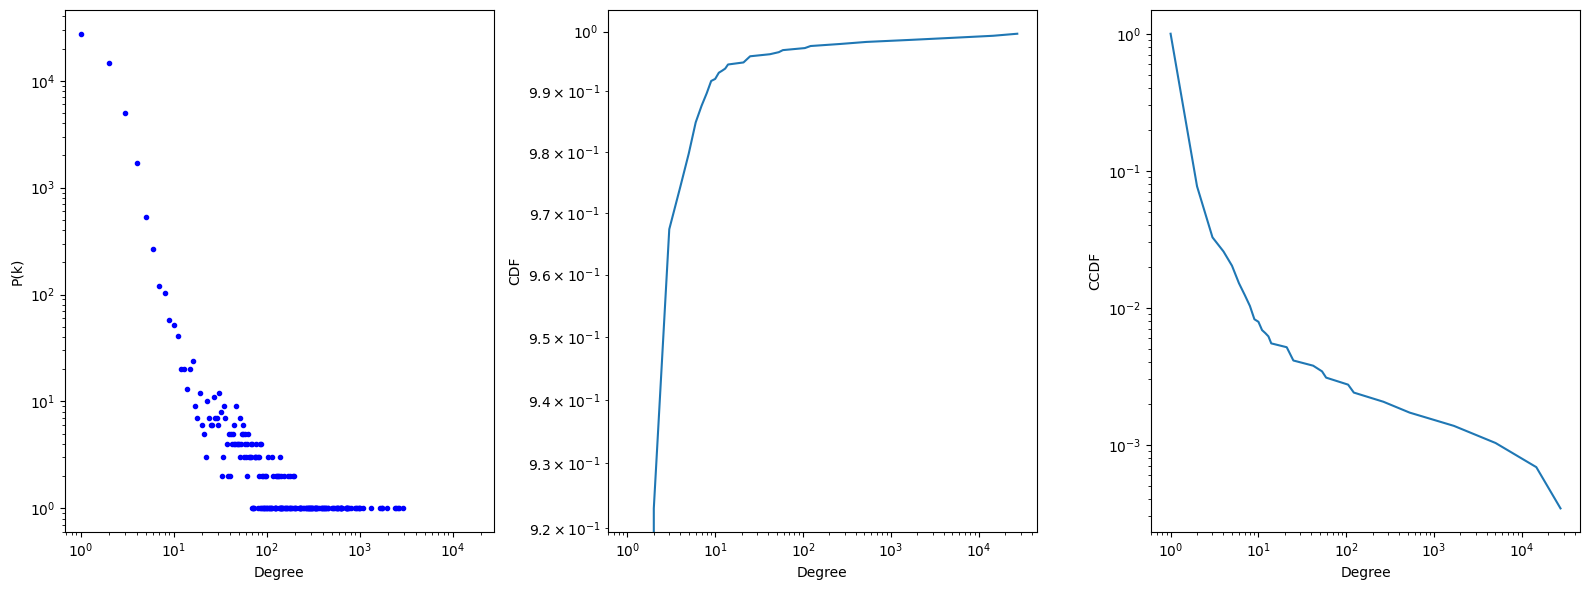

In [24]:
plot_dist(grafo_aut_ist)

La maggior part si situa tra l'1 ed i 10.

#### Connessioni maggiori

In [25]:
autori = [n for n, d in grafo_aut_ist.nodes(data=True) if d.get("tipo") == "autore"]
gradi_autori = sorted(grafo_aut_ist.degree(autori), key=lambda x: x[1], reverse=True)
print("Primi cinque autori più connessi:", gradi_autori[:5])

Primi cinque autori più connessi: [('Andrés J.M. Ferreri', 14), ('Angelo Ghezzi', 13), ('Simona Rossi', 13), ('Battista Fabio Viola', 13), ('R Ferraris', 12)]


In [26]:
istituzioni = [n for n, d in grafo_aut_ist.nodes(data=True) if d.get("tipo") == "istituzione"]
gradi_istituzioni = sorted(grafo_aut_ist.degree(istituzioni), key=lambda x: x[1], reverse=True)
print("Prime cinque istituzioni più connesse:", gradi_istituzioni[:5])

Prime cinque istituzioni più connesse: [('Istituti di Ricovero e Cura a Carattere Scientifico', 2908), ('Sapienza University of Rome', 2628), ('University of Milan', 2577), ('University of Padua', 2450), ('University of Bologna', 2379)]


In [27]:
node_ist, degree_ist = max(grafo_aut_ist.degree(), key=lambda x: x[1])
print(f'Il nodo maggiormente connesso all\'interno del grafo è {node_ist} con degree {degree_ist}')

Il nodo maggiormente connesso all'interno del grafo è Istituti di Ricovero e Cura a Carattere Scientifico con degree 2908


### Connected components

In [28]:
num_cc_ist = nx.number_connected_components(grafo_aut_ist)
cc_ist = sorted(nx.connected_components(grafo_aut_ist), key=len, reverse=True)

print(f'All\'interno del grafo autori-istituzioni ci sono {num_cc_ist} connected components')
# calcolo del giant connected component-> in genere contiene tra l'80 ed il 100% dei nodi
gcc_ist = cc_ist[0]
second_cc_ist = cc_ist[1]
print(f'Il giant connected component contiene {len(gcc_ist)} nodi, ovvero il {(len(gcc_ist)/50557)*100:.2f}% del totale.')
print(f'Il secondo connected component per larghezza contiene {len(second_cc_ist)} nodi, lo {(len(second_cc_ist)/50557)*100:.2f}% del totale.')

All'interno del grafo autori-istituzioni ci sono 55 connected components
Il giant connected component contiene 50403 nodi, ovvero il 99.70% del totale.
Il secondo connected component per larghezza contiene 8 nodi, lo 0.02% del totale.


KeyboardInterrupt: 

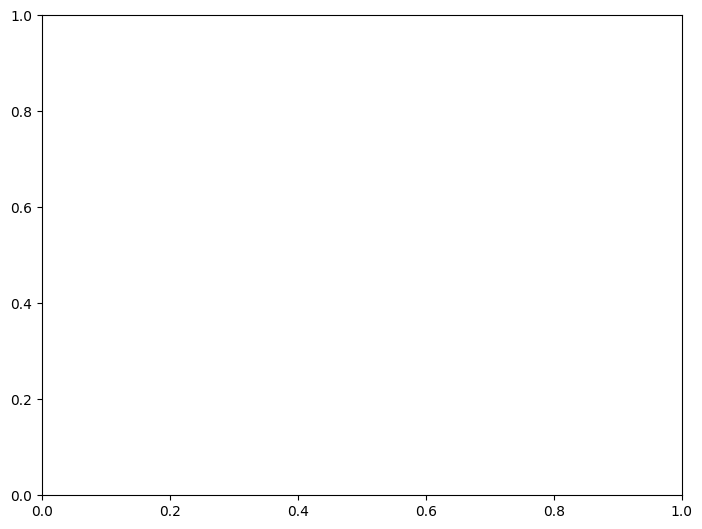

In [29]:
comp_1_ist = nx.subgraph(grafo_aut_ist, cc_ist[0])
nx.draw(comp_1_ist)

#### Analisi bipartita

In [30]:
autori = [n for n, d in grafo_aut_ist.nodes(data=True) if d.get("tipo") == "autore"]
G_autori = bipartite.projected_graph(grafo_aut_ist, autori)

autori_condivisi = 0
for node in G_autori.nodes():
    if G_autori.degree(node) > 0:
        autori_condivisi += 1

print(f'La percentuale di autori che condividono almeno una istituzione è di: {(autori_condivisi/G_autori.number_of_nodes())*100}')

La percentuale di autori che condividono almeno una istituzione è di: 99.92922716059368


#### Centralità

In [31]:
centrality = nx.degree_centrality(grafo_aut_ist)
print(sorted(centrality.items(), key=lambda x: x[1], reverse=True)[:5])

[('Istituti di Ricovero e Cura a Carattere Scientifico', 0.0575203734472664), ('Sapienza University of Rome', 0.05198196059814859), ('University of Milan', 0.05097317825777356), ('University of Padua', 0.04846111242978084), ('University of Bologna', 0.047056729171611675)]
